In [1]:
print('hola mundo')

hola mundo


# Árboles de decisión y Random Fores como modelos de regresión

Se usarán datos de precuis de venta de departamentso de caba.
La idea es usar arboles de decisión para estimar el precui de la vase en base a las features de la casa.

In [2]:
import pandas as pd

data= r'C:\Users\tocha\Documents\Labo de Datos\Precios_Departamentos_2016.csv'
df= pd.read_csv(data)

print(f'dimensión del dataset {df.shape}')
df.head()

dimensión del dataset (2232, 8)


,M2,AMBIENTES,ANTIGUEDAD,BAÑOS,LATITUD,LONGITUD,COMUNA,DOLARES
0,81,3,4,1,-34.581078,-58.449433,COMUNA 13,225000
1,69,3,20,1,-34.623129,-58.439338,COMUNA 06,140000
2,75,3,20,1,-34.604972,-58.421278,COMUNA 05,154000
3,42,2,40,1,-34.604725,-58.399524,COMUNA 03,75000
4,90,3,1,1,-34.623390,-58.504401,COMUNA 10,149900


Se busca predecir el precio de las casas. Esta variable abarca varios ordenes de magnitud, mejor trabajar con el logaritmo en base 10 de los precios.

In [3]:
import numpy as np

df['log_dolares']= np.log10(df['DOLARES'])
df.head()

,M2,AMBIENTES,ANTIGUEDAD,BAÑOS,LATITUD,LONGITUD,COMUNA,DOLARES,log_dolares
0,81,3,4,1,-34.581078,-58.449433,COMUNA 13,225000,5.352183
1,69,3,20,1,-34.623129,-58.439338,COMUNA 06,140000,5.146128
2,75,3,20,1,-34.604972,-58.421278,COMUNA 05,154000,5.187521
3,42,2,40,1,-34.604725,-58.399524,COMUNA 03,75000,4.875061
4,90,3,1,1,-34.623390,-58.504401,COMUNA 10,149900,5.175802


preparo variables para dar al modelo

In [4]:
features= ['M2', 'AMBIENTES', 'ANTIGUEDAD', 'BAÑOS', 'LATITUD', 'LONGITUD'] # lista de features
target= ['log_dolares'] #variable a predecir

X= df[features].to_numpy() # matriz de features
y= df[target].to_numpy() #vector a predecir


from sklearn.model_selection import train_test_split

seed=125

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=seed) 

Creación y ajuste del modelo

In [5]:
from sklearn.tree import DecisionTreeRegressor

arbol= DecisionTreeRegressor(max_depth=3, random_state=seed) #creo el modelo

arbol.fit(X_train, y_train) #entreno el modelo con la data

score_in_train= arbol.score(X_train, y_train) #score en los datos de train
score_in_test= arbol.score(X_test, y_test)

print(f'Train Score: {score_in_train}')
print(f'Test Score: {score_in_test}')

Train Score: 0.7773302762290755
Test Score: 0.7923881400098903


Me dio más alto en test, no tiene sentido.

visualización del árbol, útil para árboles chicos.

[Text(0.5, 0.875, 'M2 <= 88.5\nsquared_error = 0.081\nsamples = 2008\nvalue = 5.206'),
 Text(0.25, 0.625, 'M2 <= 46.5\nsquared_error = 0.032\nsamples = 1477\nvalue = 5.081'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'M2 <= 34.5\nsquared_error = 0.015\nsamples = 589\nvalue = 4.94'),
 Text(0.0625, 0.125, 'squared_error = 0.009\nsamples = 176\nvalue = 4.851'),
 Text(0.1875, 0.125, 'squared_error = 0.013\nsamples = 413\nvalue = 4.977'),
 Text(0.375, 0.375, 'M2 <= 68.5\nsquared_error = 0.022\nsamples = 888\nvalue = 5.174'),
 Text(0.3125, 0.125, 'squared_error = 0.019\nsamples = 520\nvalue = 5.12'),
 Text(0.4375, 0.125, 'squared_error = 0.015\nsamples = 368\nvalue = 5.251'),
 Text(0.75, 0.625, 'M2 <= 143.0\nsquared_error = 0.054\nsamples = 531\nvalue = 5.553'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'M2 <= 110.5\nsquared_error = 0.034\nsamples = 324\nvalue = 5.441'),
 Text(0.5625, 0.125, 'squared_error = 0.024\nsamples = 163\nvalue = 5.353'),
 Text(0.6875, 0.125, 'square

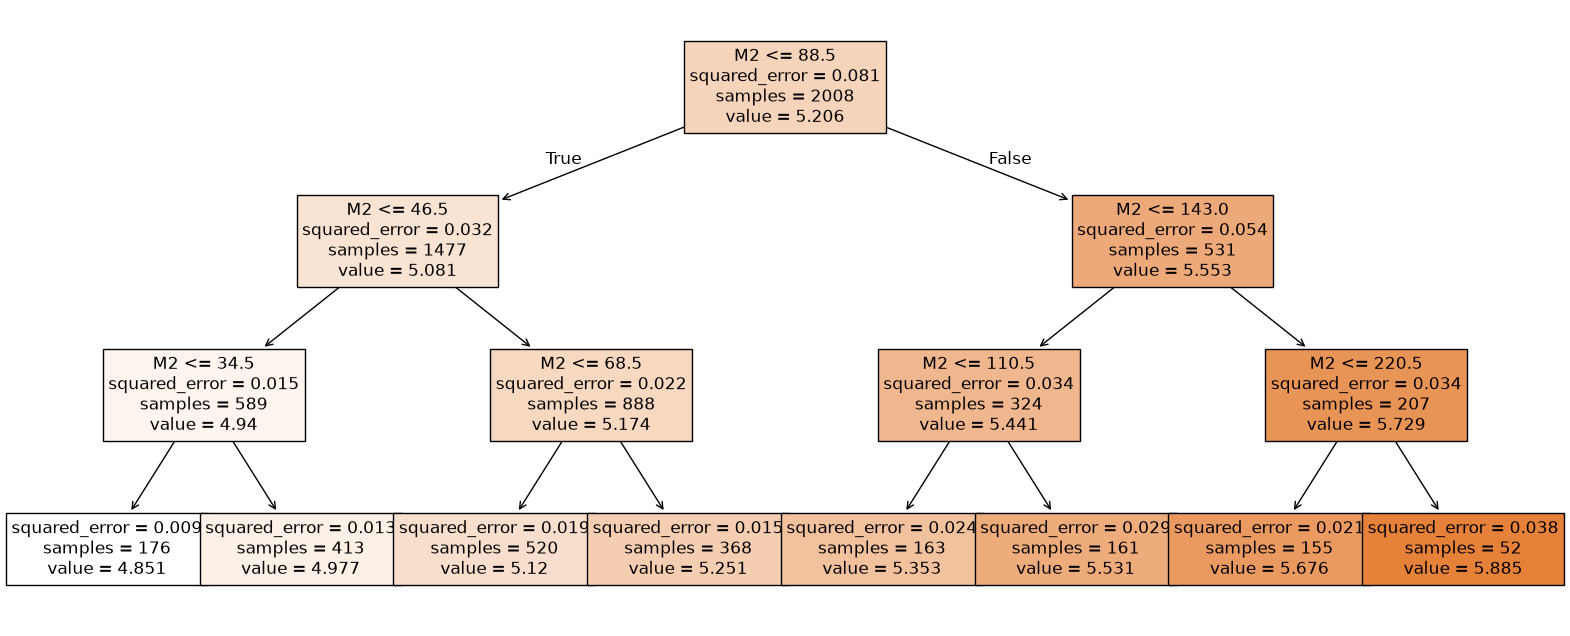

In [6]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20,8))
plot_tree(arbol, feature_names=features, fontsize=12, filled=True, ax=ax)

¿Cómo interpretamos este gráfico?

El árbol se lee de arriba hacia abajo.
Cada nodo representa una pregunta que se responde con verdadero y falso: si es verdadero tomamos la rama de la izquierda; si es falso, la de la derecha.
La pregunta está marcada por la primer línea en cada bloque.
Comencemos leyendo paso por paso:

Primer nodo (raíz del árbol), la pregunta es: ¿el departamento tiene  97.5m2  o menos?
Si es sí sigo la rama de la izquierda; si es no, voy a la derecha.

Los bloques nos dan más aún información:

samples: es la cantidad de instancias que cumplen el critero indicado. Partimos de 2008 instancias de entrenamiento y estas se separaron en dos grupos: 1565 que cumplen el primer criterio (la de los  97.5m2 ) y 443 que no lo cumplen.
value: es el valor promedio de la variable a predecir. Recordemos que esto el log10 del precio del inmueble. Así, en promedio, los departamentos con menos de  97.5m2  tiene un precio de  105.091∼123310  dólares, mientras que los que tienen más tienen un precio de  105.598∼396278  dólares.
mse: es el error medio, que esperamos se vaya haciendo chico para grupos más específicos.
En las hojas del árbol (los bloques de la base) podemos ver qué se predice para cada instancia luego de contestar las 3 preguntas que nos plantea el árbol. Por ejemplo, si tenemos un departamento cuya superficie es menor a  97.5 , que es menor a  50.5  y que es menor a  41.5m2  (es decir, siguiendo siempre la rama que está más a la izquierda) le vamos a asignar un precio de  104.898∼79068  dólares.

Ahora un modelo sin limite de profundidad para ver el overfitting
terminan describiendo exactamente los datos de entrenamiento

In [7]:
dtr= DecisionTreeRegressor(max_depth=None)

# Entrenamiento del modelo
dtr.fit(X_train, y_train)

# Score del modelo en el conjunto de entrenamiento
score_in_train = dtr.score(X_train, y_train)

# Score del modelo en el conjunto de testeo
score_in_test = dtr.score(X_test, y_test)

print('Score en el set de entrenamiento: {}'.format(score_in_train))
print('Score en el set de testeo: {}'.format(score_in_test))

Score en el set de entrenamiento: 0.9998959562823269
Score en el set de testeo: 0.8453146930268369


trin score es perfecto pero test score baja mucho, indicativo de overfitting.

Una forma de eliminar el overfitting es fijar el número de hojas.  
Además sirve por si se quiere crear una cantidad fija de precios para diferentes perfiles de compradores. Simil categorización

[Text(0.5, 0.875, 'M2 <= 88.5\nsquared_error = 0.081\nsamples = 2008\nvalue = 5.206'),
 Text(0.2, 0.625, 'M2 <= 46.5\nsquared_error = 0.032\nsamples = 1477\nvalue = 5.081'),
 Text(0.35, 0.75, 'True  '),
 Text(0.1, 0.375, 'squared_error = 0.015\nsamples = 589\nvalue = 4.94'),
 Text(0.3, 0.375, 'M2 <= 68.5\nsquared_error = 0.022\nsamples = 888\nvalue = 5.174'),
 Text(0.2, 0.125, 'squared_error = 0.019\nsamples = 520\nvalue = 5.12'),
 Text(0.4, 0.125, 'squared_error = 0.015\nsamples = 368\nvalue = 5.251'),
 Text(0.8, 0.625, 'M2 <= 143.0\nsquared_error = 0.054\nsamples = 531\nvalue = 5.553'),
 Text(0.65, 0.75, '  False'),
 Text(0.7, 0.375, 'M2 <= 110.5\nsquared_error = 0.034\nsamples = 324\nvalue = 5.441'),
 Text(0.6, 0.125, 'squared_error = 0.024\nsamples = 163\nvalue = 5.353'),
 Text(0.8, 0.125, 'squared_error = 0.029\nsamples = 161\nvalue = 5.531'),
 Text(0.9, 0.375, 'squared_error = 0.034\nsamples = 207\nvalue = 5.729')]

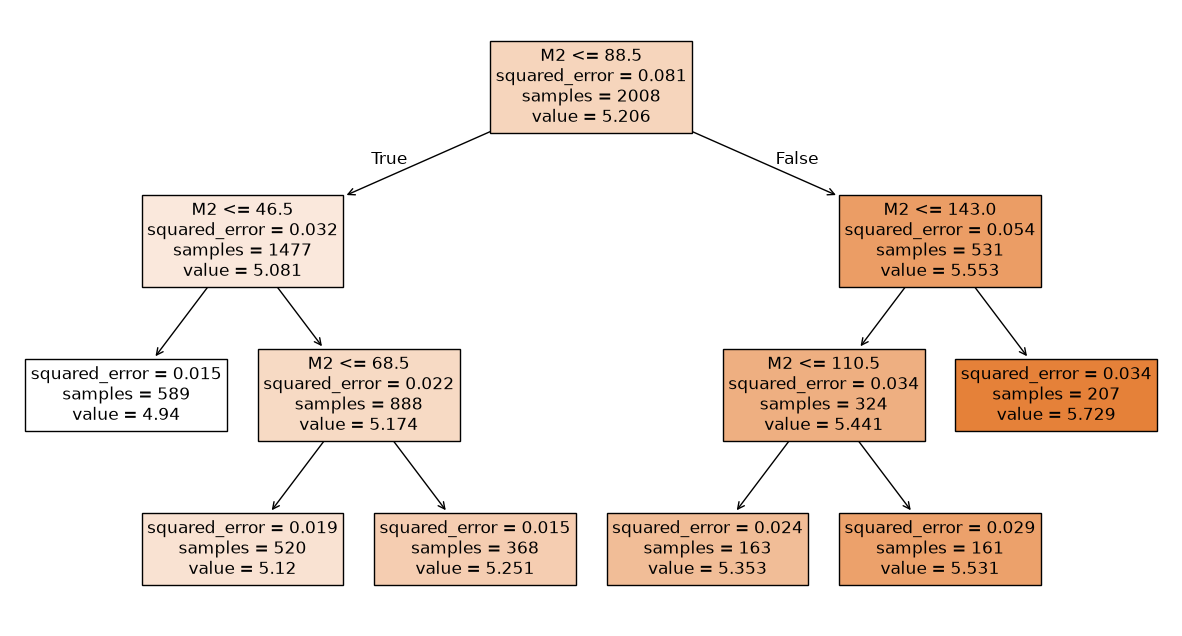

In [8]:
dtr= DecisionTreeRegressor(max_leaf_nodes=6)
# Entrenamiento
dtr.fit(X_train, y_train)

# Creamos la figura donde plotear el árbol con matplotlib
fig, ax = plt.subplots(figsize = (15, 8))

# Llamamos a la función "plot_tree" que importamos de sklearn.tree más arriba.
# Le pasamos como argumento el modelo que creamos y el nombre de los features.
# "fontsize" y "filled" son solo ajustes de la visualización
# y le decimos que plotee el arbol en la figura que creamos
plot_tree(dtr, feature_names=features, fontsize = 12, filled = True, ax = ax)

Como elige que ramificaciones truncar y quedarse con esa leaf?

Módelo donde las hojas tienen un mínimo de samples son útiles para que los valores promedios sean más robustos.

[Text(0.5909090909090909, 0.9, 'M2 <= 88.5\nsquared_error = 0.081\nsamples = 2008\nvalue = 5.206'),
 Text(0.36363636363636365, 0.7, 'M2 <= 46.5\nsquared_error = 0.032\nsamples = 1477\nvalue = 5.081'),
 Text(0.4772727272727273, 0.8, 'True  '),
 Text(0.18181818181818182, 0.5, 'M2 <= 36.5\nsquared_error = 0.015\nsamples = 589\nvalue = 4.94'),
 Text(0.09090909090909091, 0.3, 'squared_error = 0.01\nsamples = 266\nvalue = 4.879'),
 Text(0.2727272727272727, 0.3, 'squared_error = 0.014\nsamples = 323\nvalue = 4.99'),
 Text(0.5454545454545454, 0.5, 'M2 <= 68.5\nsquared_error = 0.022\nsamples = 888\nvalue = 5.174'),
 Text(0.45454545454545453, 0.3, 'LATITUD <= -34.597\nsquared_error = 0.019\nsamples = 520\nvalue = 5.12'),
 Text(0.36363636363636365, 0.1, 'squared_error = 0.012\nsamples = 250\nvalue = 5.056'),
 Text(0.5454545454545454, 0.1, 'squared_error = 0.018\nsamples = 270\nvalue = 5.178'),
 Text(0.6363636363636364, 0.3, 'squared_error = 0.015\nsamples = 368\nvalue = 5.251'),
 Text(0.818181818

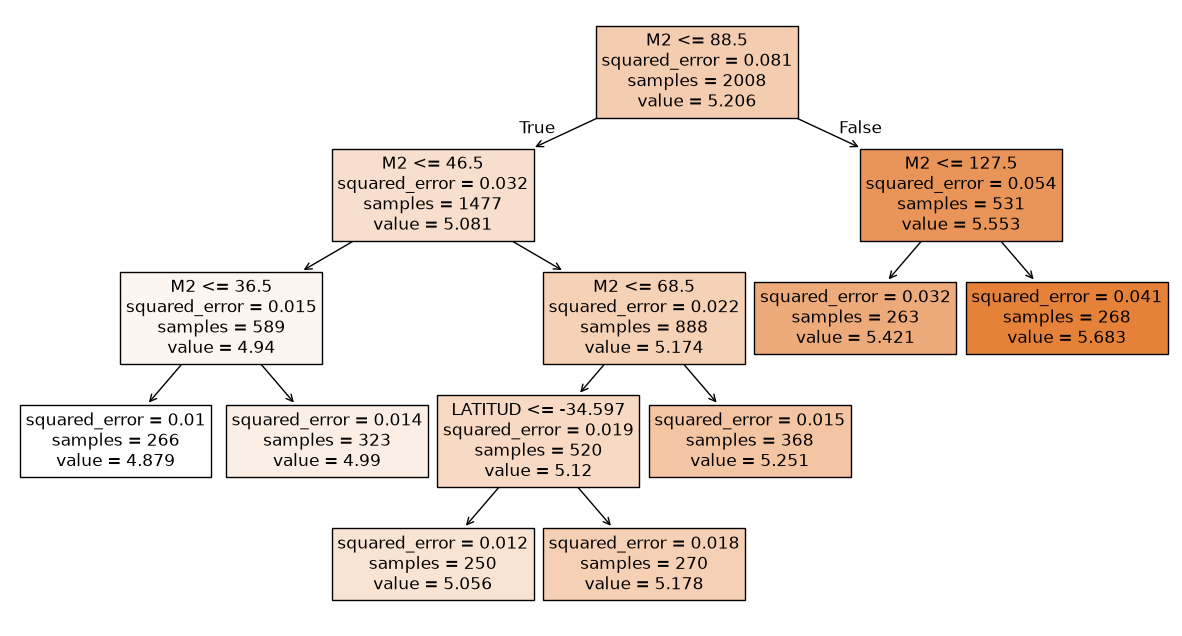

In [9]:
# Creación del árbol con al menos 250 instancias dentro de cada hoja
dtr = DecisionTreeRegressor(min_samples_leaf = 250)

# Entrenamiento
dtr.fit(X_train, y_train)

# Creamos la figura donde plotear el árbol con matplotlib
fig, ax = plt.subplots(figsize = (15, 8))

# Llamamos a la función "plot_tree" que importamos de sklearn.tree más arriba.
# Le pasamos como argumento el modelo que creamos y el nombre de los features.
# "fontsize" y "filled" son solo ajustes de la visualización
# y le decimos que plotee el arbol en la figura que creamos
plot_tree(dtr, feature_names=features, fontsize = 12, filled = True, ax = ax)

Regularización: pruning  
al construir un árbol se suele minimizar una expresión del estilo:
$$\sum_{i} (y_i - \hat{y}_i)^2 + \alpha |T|$$
donde el primer término es el cuadrado de los residuos (diferencia entre los valores reales y los valores predichos) y el segundo término es el de regularización. $|T|$ es la cantidad de hojas (nodos terminales) que tiene nuestro árbol (ver capítulo 8 de *Introduction to Statistical Learning*).

Un valor de $\alpha$ distinto de cero penaliza árboles profundos. Esta regularización es similar a *lasso* en el contexto de regresión lineal. El efecto que tiene agregar regularización es el de "podar" el árbol (*pruning* en inglés).

[Text(0.5, 0.8333333333333334, 'M2 <= 88.5\nsquared_error = 0.081\nsamples = 2008\nvalue = 5.206'),
 Text(0.25, 0.5, 'M2 <= 46.5\nsquared_error = 0.032\nsamples = 1477\nvalue = 5.081'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'squared_error = 0.015\nsamples = 589\nvalue = 4.94'),
 Text(0.375, 0.16666666666666666, 'squared_error = 0.022\nsamples = 888\nvalue = 5.174'),
 Text(0.75, 0.5, 'M2 <= 143.0\nsquared_error = 0.054\nsamples = 531\nvalue = 5.553'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'squared_error = 0.034\nsamples = 324\nvalue = 5.441'),
 Text(0.875, 0.16666666666666666, 'squared_error = 0.034\nsamples = 207\nvalue = 5.729')]

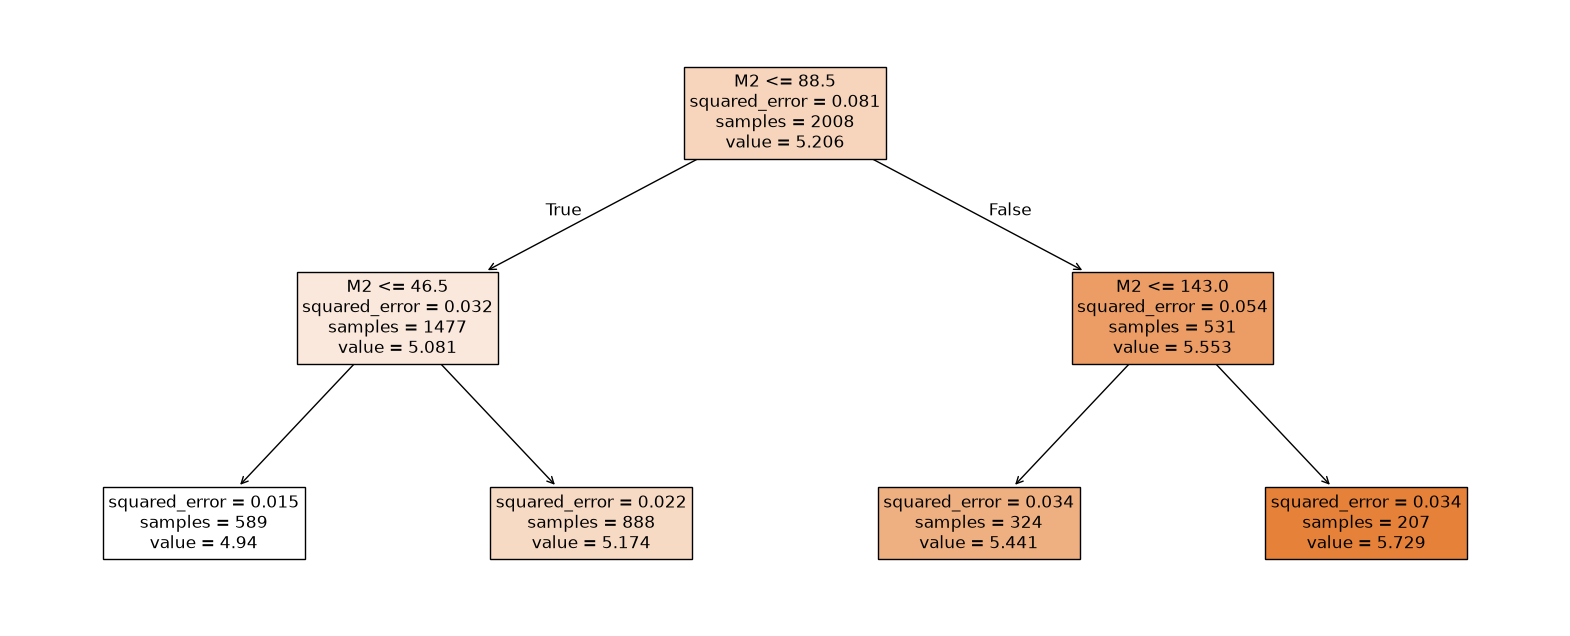

In [10]:
arbol= DecisionTreeRegressor(ccp_alpha= 0.005)
arbol.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(20,8))
plot_tree(arbol, feature_names=features, fontsize=12, filled=True, ax=ax)

para elegir alpha se puede hacer cross validation

In [11]:
from sklearn.model_selection import cross_val_score

scores=[]
alphas=np.logspace(-10,0,11)

for alpha in np.logspace(-10, 0, 11): #barrido de alphas desde 10^-10 hasta 1
    modelo=DecisionTreeRegressor(ccp_alpha=alpha)
    score= cross_val_score(modelo, X_train, y_train, cv=5)
    scores.append(score.mean())
    print(f'Valor de alpha: {alpha}, score medio: {score.mean()}')

score_max= max(scores)
index_max= scores.index(max(scores))

print(f'el mejor alpha es: {alphas[index_max]}')

Valor de alpha: 1e-10, score medio: 0.8539711300656776
Valor de alpha: 1e-09, score medio: 0.8580529409632023
Valor de alpha: 1e-08, score medio: 0.8559097758042299
Valor de alpha: 1e-07, score medio: 0.8556688636464372
Valor de alpha: 1e-06, score medio: 0.8555442583864931
Valor de alpha: 1e-05, score medio: 0.8646186617774132
Valor de alpha: 0.0001, score medio: 0.8495080933568818
Valor de alpha: 0.001, score medio: 0.7580369444321265
Valor de alpha: 0.01, score medio: 0.5518262182848944
Valor de alpha: 0.1, score medio: -0.0009597321961489769
Valor de alpha: 1.0, score medio: -0.0009597321961489769
el mejor alpha es: 1e-05


In [12]:
dtr= DecisionTreeRegressor( ccp_alpha= 10**-5)
dtr.fit(X_train, y_train)

depth= dtr.get_depth()
print(f'Profundidad del árbol={depth}')

score_in_test= dtr.score(X_test, y_test)
print(f'Score en el set de testeo: {score_in_test}')

Profundidad del árbol=16
Score en el set de testeo: 0.8551491580421351


# Random forest
Es un ensamble de árboles, construye muchos árboles arrancando con features al azar y la predicción final la hace promediando los valores predichos por cada árbol.
Aumentar la cantidad de árboles siempre mejora la predicción pero aumenta el costo computacional.

In [13]:
from sklearn.ensemble import RandomForestRegressor

In [14]:
RFr= RandomForestRegressor(n_estimators=100)
RFr.fit(X_train, y_train)

score_in_test= RFr.score(X_test, y_test)
print(f'test score: {score_in_test}')



c:\Users\tocha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


test score: 0.9350607373613911


La desventaja es que no se puede interpretar el modelo.  
Lo único posible es ver que feature es más importante para hacer buenas prediccioens.

In [15]:
feature_importancia= RFr.feature_importances_

for i in range(0,6):
    print(f'{features[i]}: {feature_importancia[i]}')


M2: 0.8107941877099806
AMBIENTES: 0.011591991153997101
ANTIGUEDAD: 0.03671478505322181
BAÑOS: 0.0089225427969723
LATITUD: 0.08164394348845207
LONGITUD: 0.05033254979737602


La importancia de cada features está medida con que tanto reduce el error al usarlo como criterio de separación en cada árbol.  
En este caso la feature más informativo es m2.

Un caso específico:

In [16]:
for i in range(0,6):
    print(f'{features[i]}: {X_test[0][i]}')

estimado= RFr.predict(X_test[0].reshape(1,-1)) #Valor predicho en log

print(f'Valor predicho= {10**estimado}')
print(f'Valor real= {10**y_test[0]}')


M2: 78.0
AMBIENTES: 3.0
ANTIGUEDAD: 50.0
BAÑOS: 1.0
LATITUD: -34.57422625832829
LONGITUD: -58.420137886629455
Valor predicho= [229719.11152609]
Valor real= [285000.]


Bucle para ver como mejora el modelo aumentando la cantidad de árboles

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


ValueError: x and y must have same first dimension, but have shapes (1999,) and (999,)

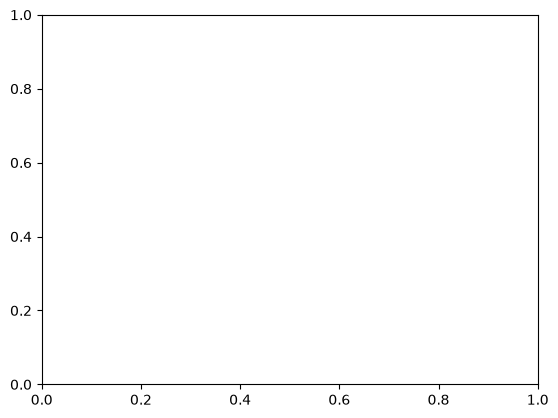

In [ ]:
scores=[]

for i in range(1,1000):
    RFr= RandomForestRegressor(n_estimators=100)
    RFr.fit(X_train, np.ravel(y_train))

    score_in_test= RFr.score(X_test, y_test)
    scores.append(score_in_test)
    print(f'{i}')



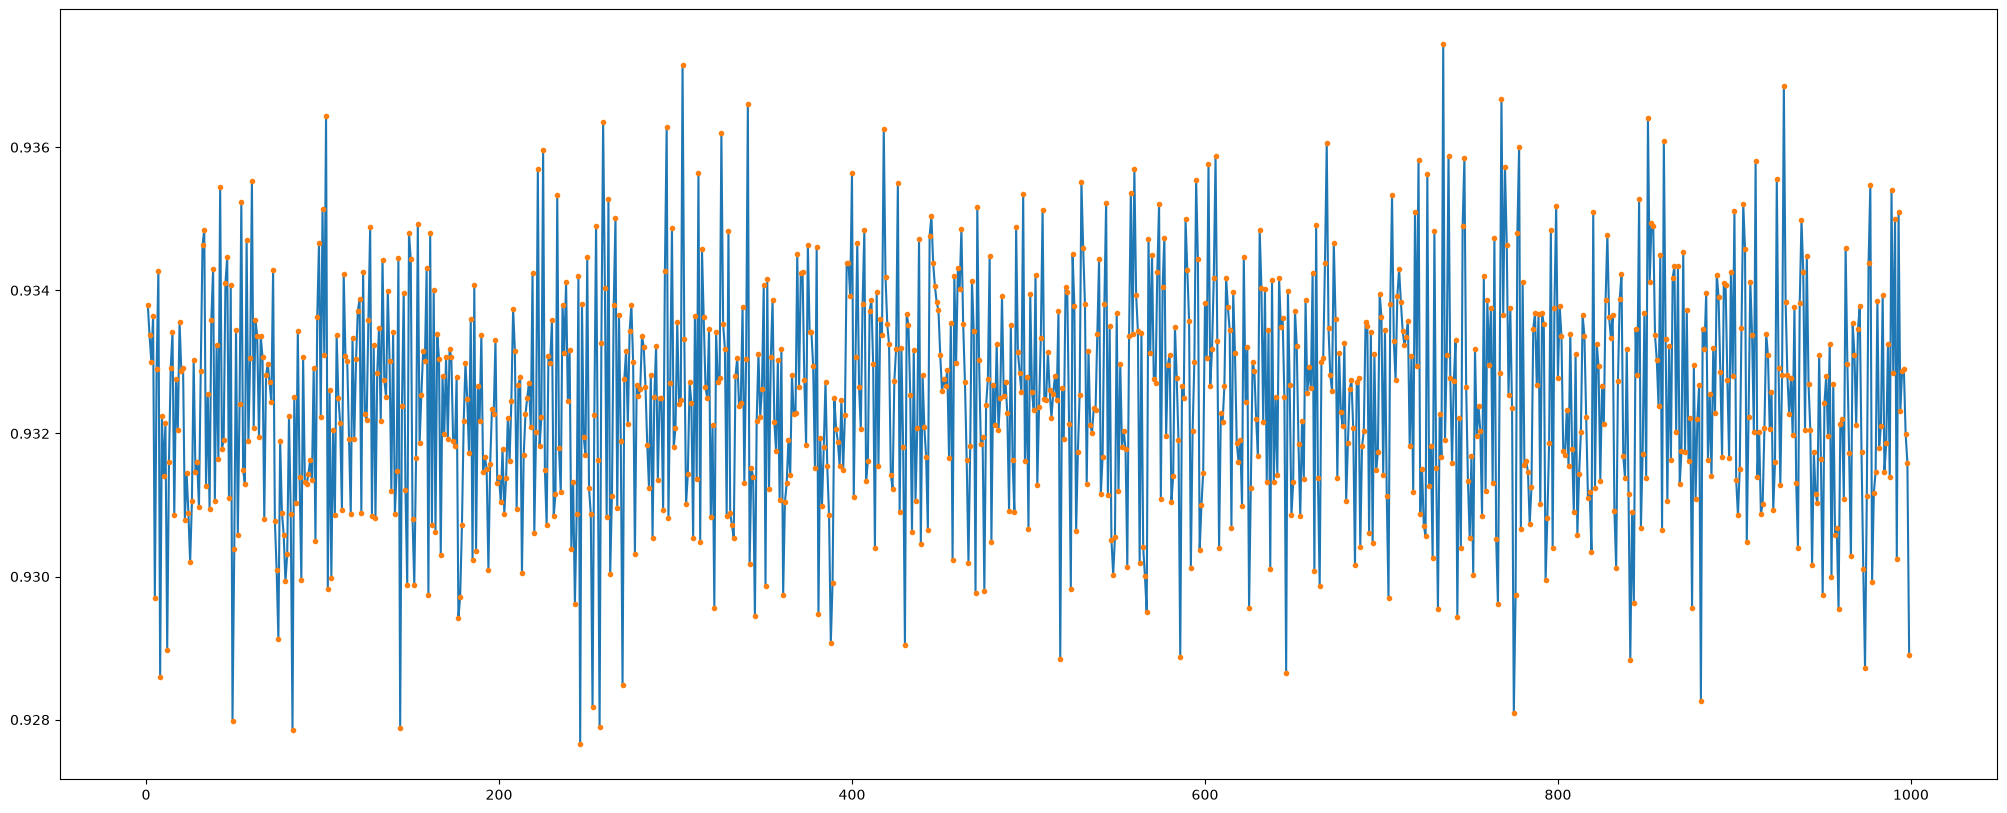

In [24]:
arboles= np.arange(1,1000)
plt.figure(figsize=(25,10))
plt.plot(arboles, scores)
plt.plot(arboles, scores, '.')

no esperaba que fuera tan ruidoso sino tipo raiz